# MedSAM on our MS subjects: GluCEST and NOE

Same idea as the full demo (notebook 01), but on our own 7T CEST data: can MedSAM outline **MS lesions** on
**GluCEST** and **NOE** images when I give it a box around each lesion?

Paper: Ma J et al. *Segment anything in medical images.* Nature Communications 15, 654 (2024).

### Data
| | subjects | lesion mask |
|---|---|---|
| GluCEST | Subject46 + 4 MS subjects from `MS_five_Sub` (GluCEST at 3 ppm) | Subject46: semi-automatic (drawn from the Z(-3 ppm) image); others: hand-drawn |
| NOE | 5 MS subjects from `MS_five_Sub` (51-offset Z-spectra, -5 to 5 ppm) | hand-drawn |

Images I give MedSAM (one at a time):
- **GluCEST map** (the fitted map at 3 ppm)
- **NOE map**: MTRasym at 3.6 ppm from the NOE Z-spectra (the offsets go in 0.2 ppm steps, 3.6 is the closest to the usual 3.5)
- **Z(-3 ppm)**: the raw saturated image at -3 ppm, which is mostly MT weighted (myelin), so MS lesions should be visible there
- **S0**: the unsaturated reference image (anatomy) for the `MS_five_Sub` subjects

### Plan
1. Load MedSAM and SAM
2. Load the data, build the images
3. EDA: lesion sizes, spectra, how visible the lesions are on each image
4. Pre-processing like the paper
5. MedSAM vs SAM vs "just fill the box" on each image type
6. Small vs big lesions
7. How exact does the box need to be?
8. 3D: sparse markers on the Subject46 lesion (like Fig. 5b)
9. What I learned

Important: MedSAM needs a box, and here the box comes from the lesion mask. So the question is not "can it find the
lesion" but "given roughly where it is, can it draw the outline". To check that MedSAM actually adds something, I
compare it with the dumbest possible answer: an ellipse that fills the box.

## 0. Imports

In [1]:
import os
import glob
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn.functional as F
from scipy import ndimage as ndi
from scipy.io import loadmat
from scipy.stats import wilcoxon
from transformers import SamModel, SamProcessor

In [2]:
np.random.seed(42)
torch.manual_seed(42)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(device)

GLUCEST_46 = '/home/jurgen/Desktop/GluCEST Deep Learning/GluCEST_Subject46_B0corrected.npz'
NOE_MS = '/home/jurgen/Desktop/MS_Anomaly /NOE_v7/noe_ms.npz'          # B0-corrected NOE spectra + hand-drawn lesions
MS_FOLDER = '/home/jurgen/Desktop/MS_five_Sub'                         # CEST3DNEW .mat files (GluCEST maps, S0)

cuda


## 1. Load the models
Same as notebook 01: the full MedSAM conversion (`flaviagiammarino`, not `wanglab` which has SAM's encoder) and the
original SAM.

In [3]:
medsam = SamModel.from_pretrained('flaviagiammarino/medsam-vit-base').to(device)
sam = SamModel.from_pretrained('facebook/sam-vit-base').to(device)
samProcessor = SamProcessor.from_pretrained('facebook/sam-vit-base')
_ = medsam.eval()
_ = sam.eval()

print(f'MedSAM image encoder: {sum(p.numel() for p in medsam.vision_encoder.parameters()):,} parameters (paper: 89,670,912)')

Could not reach the Hub ([Errno 104] Connection reset by peer). Using cached commit hash for 'flaviagiammarino/medsam-vit-base'.


MedSAM image encoder: 89,670,912 parameters (paper: 89,670,912)


## 2. Load the data

### NOE: 5 MS subjects
Already B0-corrected in the NOE_v7 project (`prep_noe.py`): Z-spectra on 51 offsets, slices 1-10 of the slab, brain
ROI, tissue segmentation and the hand-drawn lesion masks.

In [4]:
noe = np.load(NOE_MS)
for k in noe.files:
    print(k, noe[k].shape, noe[k].dtype)

zspec (5, 51, 240, 196, 10) float32
roi (5, 240, 196, 10) bool
seg (5, 240, 196, 10) int8
lesion (5, 240, 196, 10) bool
offsets (51,) float64
subjects (5,) <U13


In [5]:
noe_subjects = list(noe['subjects'])
noe_offsets = noe['offsets']
print(noe_subjects)
print(noe_offsets)

[np.str_('Subject_12_43'), np.str_('Subject_18_73'), np.str_('Subject_19_74'), np.str_('Subject_22_23'), np.str_('Subject_23_77')]
[-5.  -4.8 -4.6 -4.4 -4.2 -4.  -3.8 -3.6 -3.4 -3.2 -3.  -2.8 -2.6 -2.4
 -2.2 -2.  -1.8 -1.6 -1.4 -1.2 -1.  -0.8 -0.6 -0.4 -0.2  0.   0.2  0.4
  0.6  0.8  1.   1.2  1.4  1.6  1.8  2.   2.2  2.4  2.6  2.8  3.   3.2
  3.4  3.6  3.8  4.   4.2  4.4  4.6  4.8  5. ]


The raw spectra are noisy, so I denoise them like in my UAD work: truncated SVD of the (ROI voxels x offsets)
matrix of each subject. Rank 6 for NOE (what I used in NOE_v7).

In [6]:
def svd_denoise(zspec, roi, rank):
    # zspec (offsets, H, W, Z), roi (H, W, Z)
    voxels = zspec[:, roi].T.astype(np.float64)        # (n voxels, offsets)
    mean = voxels.mean(axis=0)
    U, S, Vt = np.linalg.svd(voxels - mean, full_matrices=False)
    clean = mean + (U[:, :rank] * S[:rank]) @ Vt[:rank]
    out = np.zeros_like(zspec)
    out[:, roi] = clean.T
    return out

In [7]:
def offset_index(offsets, ppm):
    return int(np.argmin(np.abs(offsets - ppm)))

i_m35 = offset_index(noe_offsets, -3.6)      # no 3.5 on a 0.2 ppm grid, and both sides have to be the same offset
i_p35 = offset_index(noe_offsets, 3.6)
i_m3 = offset_index(noe_offsets, -3.0)
print('offsets used:', noe_offsets[i_m35], noe_offsets[i_p35], noe_offsets[i_m3])

offsets used: -3.5999999999999996 3.5999999999999996 -3.0


In [8]:
subjects = {}     # everything per subject goes in here

for s, name in enumerate(noe_subjects):
    roi = noe['roi'][s]
    z = svd_denoise(noe['zspec'][s], roi, rank=6)
    subjects[name] = {
        'roi': roi,
        'seg': noe['seg'][s],
        'lesion': noe['lesion'][s] & roi,
        'NOE map': (z[i_p35] - z[i_m35]) * roi,          # MTRasym at 3.6 ppm
        'Z(-3 ppm)': z[i_m3] * roi,
    }
    print(name, 'ROI voxels', roi.sum(), 'lesion voxels', subjects[name]['lesion'].sum())

Subject_12_43 ROI voxels 132936 lesion voxels 827


Subject_18_73 ROI voxels 164698 lesion voxels 631


Subject_19_74 ROI voxels 150800 lesion voxels 672


Subject_22_23 ROI voxels 154124 lesion voxels 2934


Subject_23_77 ROI voxels 158560 lesion voxels 1090


### GluCEST maps and S0 of the same subjects
From the `CEST3DNEW` .mat files in `MS_five_Sub` (12 slices, I keep 1-10 like the NOE data). One subject
(Subject_12_43) has a 3.5 ppm CEST map instead of GluCEST, so no GluCEST for that one.

In [9]:
for name in noe_subjects:
    mat_file = glob.glob(os.path.join(MS_FOLDER, name, 'CEST3DNEW*.mat'))[0]
    out = loadmat(mat_file, squeeze_me=True, struct_as_record=False, variable_names=['output'])['output']
    roi = subjects[name]['roi']
    subjects[name]['S0'] = out.S0image[:, :, 1:-1] * roi
    if out.CESTppm == 3:
        subjects[name]['GluCEST map'] = np.nan_to_num(out.CESTmap[:, :, 1:-1]) * roi
    print(name, 'CEST ppm', out.CESTppm, '| S0', subjects[name]['S0'].shape)

Subject_12_43 CEST ppm -3.5 | S0 (240, 196, 10)


Subject_18_73 CEST ppm 3 | S0 (240, 196, 10)


Subject_19_74 CEST ppm 3 | S0 (240, 196, 10)


Subject_22_23 CEST ppm 3 | S0 (240, 196, 10)


Subject_23_77 CEST ppm 3 | S0 (240, 196, 10)


### GluCEST: Subject46
18 offsets around +-3 ppm, B0-corrected, with the fitted GluCEST map. There is no radiologist mask for Subject46;
the lesion mask comes from my semi-automatic function (threshold the Z(-3 ppm) image inside a disc around the lesion).
I copy it here so the notebook doesn't need the other project.

In [10]:
g = np.load(GLUCEST_46)
for k in g.files:
    print(k, g[k].shape)
print(g['imageShape'], g['ppmlist'])

zspecN (564480, 18)
voxelInds (145765,)
imageShape (5,)
glucest (564480,)
b0map (564480,)
b1map (564480,)
segmask (564480,)
ppmlist (18,)
target_ppm ()
[  1 240 196  12  18] [-4.2 -3.9 -3.6 -3.3 -3.  -2.7 -2.4 -2.1 -1.8  1.8  2.1  2.4  2.7  3.
  3.3  3.6  3.9  4.2]


In [11]:
n, H, W, Zn, L = g['imageShape']
roi46 = np.zeros(n * H * W * Zn, dtype=bool)
roi46[g['voxelInds']] = True
roi46 = roi46.reshape(H, W, Zn)

z46_raw = np.nan_to_num(g['zspecN'].reshape(H, W, Zn, L)).transpose(3, 0, 1, 2) * roi46     # (offsets, H, W, Z)
glucest46 = np.nan_to_num(g['glucest'].reshape(H, W, Zn)) * roi46
seg46 = g['segmask'].reshape(H, W, Zn)
ppm46 = g['ppmlist']
print(z46_raw.shape, glucest46.shape)

(18, 240, 196, 12) (240, 196, 12)


In [12]:
def make_lesion_mask_46(z_m3, roi, center=(123, 77), r=11, slices=range(3, 11), k_sd=1.0):
    # from spatial_glucest.py: inside a disc around the lesion keep voxels brighter than the surrounding ring
    H, W, Zn = roi.shape
    mask = np.zeros((H, W, Zn), dtype=bool)
    hh, ww = np.mgrid[:H, :W]
    d2 = (hh - center[0]) ** 2 + (ww - center[1]) ** 2
    disc = d2 <= r * r
    ring = (d2 <= (2 * r) ** 2) & (d2 > r * r)
    for z in slices:
        im = ndi.gaussian_filter(z_m3[:, :, z], 1.0)
        background = im[ring & roi[:, :, z]]
        candidate = disc & roi[:, :, z] & (im > np.median(background) + k_sd * background.std())
        lab, n_pieces = ndi.label(candidate)
        if n_pieces == 0:
            continue
        sizes = np.bincount(lab.ravel())[1:]
        if sizes.max() >= 10:
            mask[:, :, z] = ndi.binary_fill_holes(lab == 1 + np.argmax(sizes))
    return mask

i46_m3 = offset_index(ppm46, -3.0)
lesion46 = make_lesion_mask_46(z46_raw[i46_m3], roi46)
z46 = svd_denoise(z46_raw, roi46, rank=4)                  # rank 4 like GluCEST v7

keep = slice(1, -1)                                         # slices 1-10 like the others
subjects['Subject46'] = {'roi': roi46[:, :, keep], 'seg': seg46[:, :, keep], 'lesion': lesion46[:, :, keep],
                         'GluCEST map': glucest46[:, :, keep], 'Z(-3 ppm)': z46[i46_m3][:, :, keep] * roi46[:, :, keep]}
print('Subject46 lesion voxels:', subjects['Subject46']['lesion'].sum())

Subject46 lesion voxels: 1586


In [13]:
contrasts = ['GluCEST map', 'NOE map', 'Z(-3 ppm)', 'S0']
overview = []
for name, d in subjects.items():
    row = {'subject': name, 'lesion voxels': d['lesion'].sum(),
           'slices with lesion': int(d['lesion'].any(axis=(0, 1)).sum())}
    for c in contrasts:
        row[c] = 'yes' if c in d else '-'
    overview.append(row)
pd.DataFrame(overview)

,subject,lesion voxels,slices with lesion,GluCEST map,NOE map,Z(-3 ppm),S0
0,Subject_12_43,827,8,-,yes,yes,yes
1,Subject_18_73,631,10,yes,yes,yes,yes
2,Subject_19_74,672,10,yes,yes,yes,yes
3,Subject_22_23,2934,10,yes,yes,yes,yes
4,Subject_23_77,1090,10,yes,yes,yes,yes
5,Subject46,1586,8,yes,-,yes,-


## 3. EDA

### What do the images look like?
For every subject the slice with the most lesion, all image types, lesion in cyan.

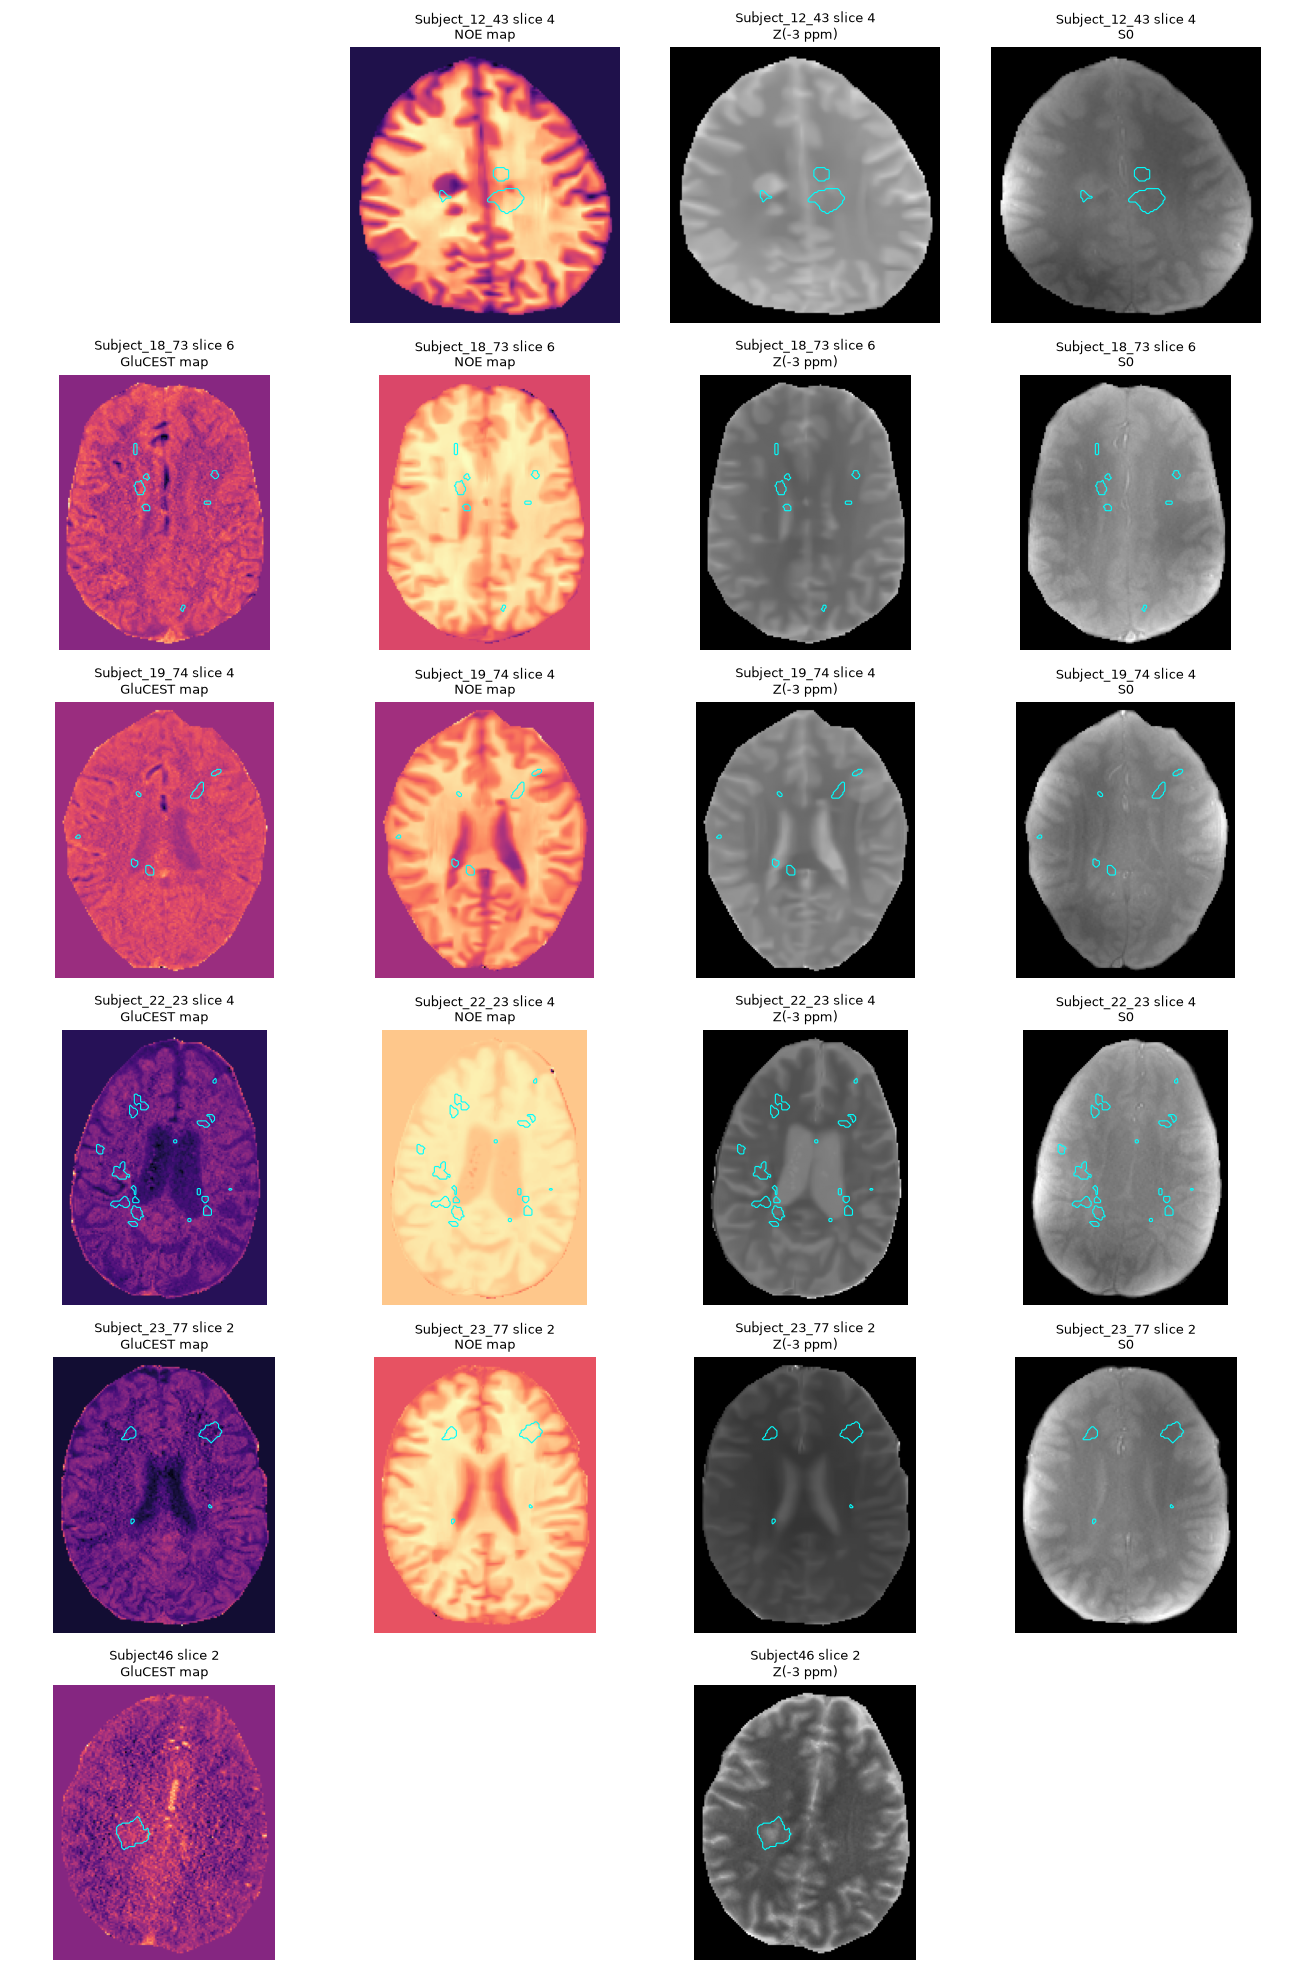

In [14]:
def lesion_slice(d):
    return int(np.argmax(d['lesion'].sum(axis=(0, 1))))

def crop_to_brain(img, roi, pad=5):
    rows, cols = np.where(roi)
    return img[rows.min() - pad:rows.max() + pad, cols.min() - pad:cols.max() + pad]

fig, ax = plt.subplots(len(subjects), 4, figsize=(13, 3.3 * len(subjects)))
for r, (name, d) in enumerate(subjects.items()):
    z = lesion_slice(d)
    for c, contrast in enumerate(contrasts):
        a = ax[r, c]
        a.axis('off')
        if contrast not in d:
            continue
        a.imshow(crop_to_brain(d[contrast][:, :, z], d['roi'][:, :, z]), cmap='gray' if contrast in ['S0', 'Z(-3 ppm)'] else 'magma')
        a.contour(crop_to_brain(d['lesion'][:, :, z], d['roi'][:, :, z]), [0.5], colors='cyan', linewidths=0.8)
        a.set_title(f'{name} slice {z}\n{contrast}', fontsize=9)
plt.tight_layout()
plt.show()

### How big are the lesions? (per slice, per separate piece)

In [15]:
pieces = []
for name, d in subjects.items():
    for z in range(d['lesion'].shape[2]):
        lab, n_pieces = ndi.label(d['lesion'][:, :, z])
        for k in range(1, n_pieces + 1):
            pieces.append({'subject': name, 'slice': z, 'pixels': int((lab == k).sum())})
pieces = pd.DataFrame(pieces)
pieces.groupby('subject')['pixels'].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
subject,,,,,,,,
Subject46,8.0,198.2,28.6,166.0,176.0,191.0,226.5,236.0
Subject_12_43,19.0,43.5,48.6,1.0,9.0,25.0,66.0,157.0
Subject_18_73,42.0,15.0,14.3,1.0,6.0,9.5,20.2,64.0
Subject_19_74,57.0,11.8,10.6,2.0,6.0,9.0,13.0,58.0
Subject_22_23,113.0,26.0,23.8,2.0,9.0,17.0,30.0,118.0
Subject_23_77,62.0,17.6,20.3,2.0,6.0,11.0,20.8,103.0


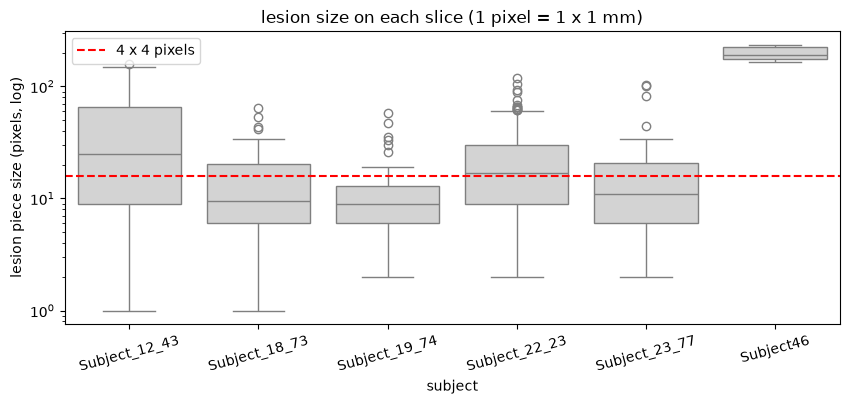

In [16]:
plt.figure(figsize=(10, 3.8))
sns.boxplot(data=pieces, x='subject', y='pixels', color='lightgray')
plt.yscale('log')
plt.axhline(16, color='red', linestyle='--', label='4 x 4 pixels')
plt.ylabel('lesion piece size (pixels, log)')
plt.title('lesion size on each slice (1 pixel = 1 x 1 mm)')
plt.legend()
plt.xticks(rotation=15)
plt.show()

##### Most NOE-subject lesions are tiny: a median of 9-25 pixels per piece, so a lot of them are about 3 x 3 to 5 x 5 pixels. Subject46 is one big round lesion. In notebook 01 MedSAM had trouble with tiny targets (pathology nuclei), so this will be hard.

### Spectra: lesion vs normal-appearing white matter (NAWM) vs grey matter
Segmentation labels: 2 = grey matter, 3 = white matter.

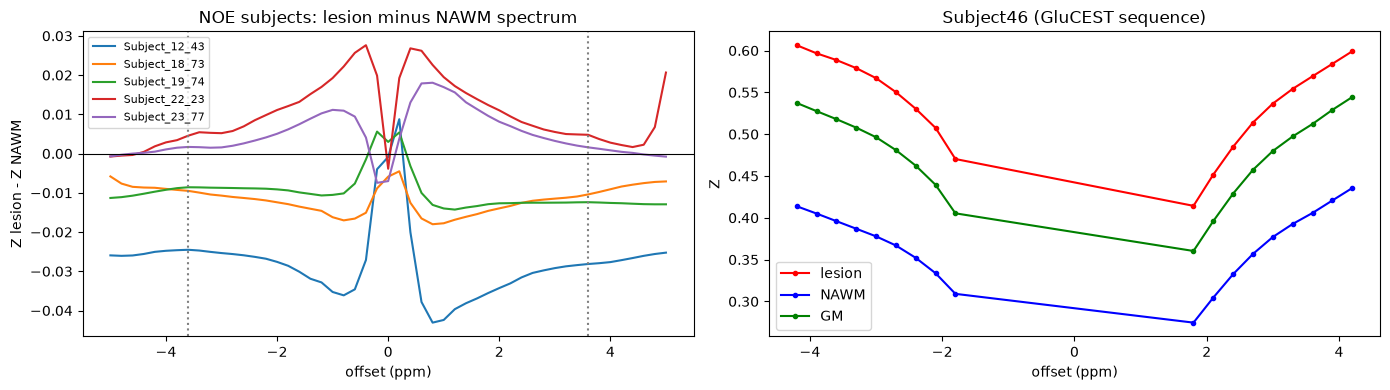

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for name in noe_subjects:
    s = noe_subjects.index(name)
    z = svd_denoise(noe['zspec'][s], noe['roi'][s], rank=6)
    d = subjects[name]
    nawm = (d['seg'] == 3) & ~d['lesion']
    ax[0].plot(noe_offsets, z[:, d['lesion']].mean(axis=1) - z[:, nawm].mean(axis=1), label=name)
ax[0].axhline(0, color='black', linewidth=0.8)
ax[0].axvline(-3.6, color='gray', linestyle=':')
ax[0].axvline(3.6, color='gray', linestyle=':')
ax[0].set_xlabel('offset (ppm)')
ax[0].set_ylabel('Z lesion - Z NAWM')
ax[0].set_title('NOE subjects: lesion minus NAWM spectrum')
ax[0].legend(fontsize=8)

d = subjects['Subject46']
for label, m, color in [('lesion', lesion46, 'red'), ('NAWM', (seg46 == 3) & ~lesion46, 'blue'), ('GM', seg46 == 2, 'green')]:
    ax[1].plot(ppm46, z46[:, m].mean(axis=1), 'o-', color=color, label=label, markersize=3)
ax[1].set_xlabel('offset (ppm)')
ax[1].set_ylabel('Z')
ax[1].set_title('Subject46 (GluCEST sequence)')
ax[1].legend()
plt.tight_layout()
plt.show()

### How visible is the lesion on each image type?
For every lesion: mean inside vs a 3 pixel ring of brain tissue around it (same slice), divided by the standard
deviation of the ring. I call it the contrast d'. If |d'| is small the lesion just isn't in the image.

In [18]:
contrast_rows = []
for name, d in subjects.items():
    for z in range(d['lesion'].shape[2]):
        lab, n_pieces = ndi.label(d['lesion'][:, :, z])
        for k in range(1, n_pieces + 1):
            piece = lab == k
            if piece.sum() < 5:
                continue
            ring = ndi.binary_dilation(piece, iterations=3) & ~d['lesion'][:, :, z] & d['roi'][:, :, z]
            for c in contrasts:
                if c not in d:
                    continue
                img = d[c][:, :, z]
                contrast_rows.append({'subject': name, 'image': c, 'pixels': piece.sum(),
                                      "d'": (img[piece].mean() - img[ring].mean()) / (img[ring].std() + 1e-8)})
contrast_df = pd.DataFrame(contrast_rows)
contrast_df.pivot_table(index='subject', columns='image', values="d'", aggfunc='median').round(2)

image,GluCEST map,NOE map,S0,Z(-3 ppm)
subject,,,,
Subject46,1.05,NaN,NaN,5.78
Subject_12_43,NaN,0.19,-0.16,-0.15
Subject_18_73,0.09,0.01,-0.08,-0.03
Subject_19_74,0.21,0.09,-0.02,-0.09
Subject_22_23,0.04,0.09,0.01,-0.06
Subject_23_77,-0.13,0.04,-0.19,-0.18


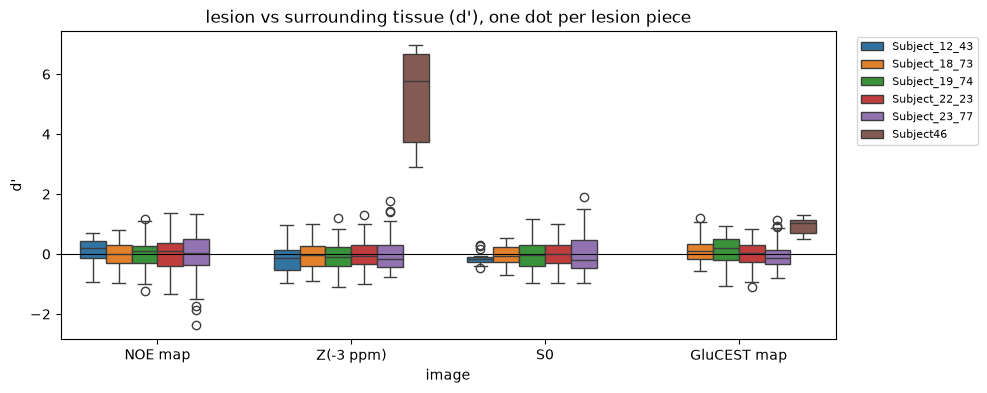

In [19]:
plt.figure(figsize=(10, 4))
sns.boxplot(data=contrast_df, x='image', y="d'", hue='subject')
plt.axhline(0, color='black', linewidth=0.8)
plt.title("lesion vs surrounding tissue (d'), one dot per lesion piece")
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
plt.show()

##### This is the most important result of the EDA. For the 5 `MS_five_Sub` subjects the lesions are basically **not visible** on any of the 4 images: median |d'| is at most 0.21 (GluCEST, NOE, Z(-3 ppm) and S0 all similar). In the pictures above you can't see a spot inside the cyan outlines either. Subject46 is completely different: its lesion stands out strongly on Z(-3 ppm) (d' 5.8) and a bit on the GluCEST map (d' 1.1). (The Subject46 mask was made by thresholding Z(-3 ppm), so its d' on that image is partly circular.)

##### My guess is the `MS_five_Sub` lesions were drawn on a different scan (FLAIR / MP2RAGE) where they are visible, and at 7T CEST resolution and contrast they mostly disappear. Same conclusion as my NOE_v7 anomaly detection work, where these lesions weren't detected either.

## 4. Pre-processing like the paper
MR images: clip to the 0.5-99.5 percentile (of the brain voxels), scale to 0-255, 3 channels, resize to 1024 x 1024,
scale to 0-1. In notebook 01 the bicubic resize with skimage took ~1.7 s per image on the CPU, so here I do the
same bicubic resize with torch on the GPU (for upsampling a 240 x 196 slice it's the same thing).

In [20]:
def to_uint8(img, roi):
    values = img[roi]
    lo, hi = np.percentile(values, [0.5, 99.5])
    out = np.clip((img - lo) / (hi - lo + 1e-8), 0, 1) * 255
    out[~roi] = 0
    return out.astype(np.uint8)

def to_3_channels(img):
    return np.repeat(img[:, :, None], 3, axis=-1)

def medsam_embedding(img_3c):
    x = torch.tensor(img_3c, dtype=torch.float32).permute(2, 0, 1).unsqueeze(0).to(device)
    x = F.interpolate(x, size=(1024, 1024), mode='bicubic', align_corners=False)
    x = (x - x.min()) / torch.clamp(x.max() - x.min(), min=1e-8)
    with torch.no_grad():
        emb = medsam.get_image_embeddings(x)
    return emb

In [21]:
d = subjects['Subject46']
z = lesion_slice(d)
example = to_3_channels(to_uint8(d['GluCEST map'][:, :, z], d['roi'][:, :, z]))
print(example.shape, example.dtype, example.min(), example.max())

t0 = time.time()
emb = medsam_embedding(example)
torch.cuda.synchronize()
print(emb.shape, f'{(time.time() - t0) * 1000:.0f} ms with the GPU resize')

(240, 196, 3) uint8 0 255


torch.Size([1, 256, 64, 64]) 1021 ms with the GPU resize


Same functions as notebook 01 for the boxes, SAM, and the scores:

In [22]:
def medsam_box(emb, boxes, H, W):
    boxes = np.array(boxes, dtype=float).reshape(-1, 4)
    b = torch.tensor(boxes / np.array([W, H, W, H]) * 1024, dtype=torch.float32)[None].to(device)
    with torch.no_grad():
        out = medsam(image_embeddings=emb, input_boxes=b, multimask_output=False)
    low_res = torch.sigmoid(out.pred_masks[0, :, 0])
    prob = F.interpolate(low_res[:, None], size=(H, W), mode='bilinear', align_corners=False)[:, 0]
    return prob.cpu().numpy() > 0.5

def sam_box(img_3c, boxes):
    inputs = samProcessor(img_3c, return_tensors='pt').to(device)
    H, W = img_3c.shape[:2]
    scale = 1024 / max(H, W)
    b = torch.tensor(np.array(boxes, dtype=float).reshape(-1, 4) * scale, dtype=torch.float32)[None].to(device)
    with torch.no_grad():
        emb = sam.get_image_embeddings(inputs['pixel_values'])
        out = sam(image_embeddings=emb, input_boxes=b, multimask_output=False)
    masks = samProcessor.image_processor.post_process_masks(out.pred_masks.cpu(), inputs['original_sizes'].cpu(),
                                                            inputs['reshaped_input_sizes'].cpu())
    return masks[0][:, 0].numpy()

def ellipse_in_box(boxes, H, W):
    # the "dumb" baseline: fill an ellipse that touches the 4 sides of each box
    yy, xx = np.mgrid[:H, :W]
    out = np.zeros((len(boxes), H, W), dtype=bool)
    for i, (x0, y0, x1, y1) in enumerate(boxes):
        cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
        rx, ry = max((x1 - x0) / 2, 0.5), max((y1 - y0) / 2, 0.5)
        out[i] = ((xx - cx) / rx) ** 2 + ((yy - cy) / ry) ** 2 <= 1
    return out

def dice(pred, gt):
    if pred.sum() + gt.sum() == 0:
        return 1.0
    return 2 * (pred & gt).sum() / (pred.sum() + gt.sum())

def nsd(pred, gt, tol=2.0, spacing=None):
    pred = pred.astype(bool)
    gt = gt.astype(bool)
    if pred.sum() == 0 or gt.sum() == 0:
        return 0.0
    if spacing is None:
        spacing = [1.0] * pred.ndim
    pred_border = pred ^ ndi.binary_erosion(pred)
    gt_border = gt ^ ndi.binary_erosion(gt)
    dist_to_gt = ndi.distance_transform_edt(~gt_border, sampling=spacing)
    dist_to_pred = ndi.distance_transform_edt(~pred_border, sampling=spacing)
    good = (dist_to_gt[pred_border] <= tol).sum() + (dist_to_pred[gt_border] <= tol).sum()
    return good / (pred_border.sum() + gt_border.sum())

def box_from_mask(m, pad=2):
    rows, cols = np.where(m)
    H, W = m.shape
    return np.array([max(cols.min() - pad, 0), max(rows.min() - pad, 0),
                     min(cols.max() + pad, W - 1), min(rows.max() + pad, H - 1)], dtype=float)

## 5. MedSAM vs SAM vs "fill the box"

For every subject and every image type: one box per lesion piece (pieces of at least 5 pixels, 2 pixel margin). To
keep the demo quick I only use the **5 middle slices** of each subject's lesions (`N_SLICES`). Scores per subject
over those slices:
- **DSC** and **NSD** (tolerance 2 mm = 2 pixels in-plane, slices are 2 mm)
- also DSC per lesion piece, to see if size matters

In [23]:
MIN_PIXELS = 5
N_SLICES = 5        # lesion slices per subject (the middle ones), make bigger to use all

def middle_lesion_slices(d):
    zs = np.where(d['lesion'].any(axis=(0, 1)))[0]
    middle = len(zs) // 2
    start = max(middle - N_SLICES // 2, 0)
    return zs[start:start + N_SLICES]

def lesion_boxes(lesion_2d):
    lab, n_pieces = ndi.label(lesion_2d)
    boxes = []
    for k in range(1, n_pieces + 1):
        if (lab == k).sum() >= MIN_PIXELS:
            boxes.append(box_from_mask(lab == k))
    return np.array(boxes), lab

d = subjects['Subject_22_23']
z = lesion_slice(d)
boxes, lab = lesion_boxes(d['lesion'][:, :, z])
print('Subject_22_23 slice', z, ':', len(boxes), 'boxes')
print(boxes[:3])

Subject_22_23 slice 4 : 15 boxes
[[124.  61. 129.  67.]
 [ 74.  71.  86.  84.]
 [ 71.  78.  79.  89.]]


In [24]:
subject_rows = []
piece_rows = []
predictions = {}       # (subject, image, method) -> 3D prediction

t_start = time.time()
for name, d in subjects.items():
    H, W, Zn = d['lesion'].shape
    for c in contrasts:
        if c not in d:
            continue
        pred = {'MedSAM': np.zeros((H, W, Zn), bool), 'SAM': np.zeros((H, W, Zn), bool), 'ellipse': np.zeros((H, W, Zn), bool)}
        for z in middle_lesion_slices(d):
            boxes, lab = lesion_boxes(d['lesion'][:, :, z])
            if len(boxes) == 0:
                continue
            img = to_3_channels(to_uint8(d[c][:, :, z], d['roi'][:, :, z]))
            masks = {'MedSAM': medsam_box(medsam_embedding(img), boxes, H, W),
                     'SAM': sam_box(img, boxes),
                     'ellipse': ellipse_in_box(boxes, H, W)}
            for method, m in masks.items():
                pred[method][:, :, z] = m.any(axis=0) & d['roi'][:, :, z]
            # per piece: the mask from that piece's own box, against that piece
            for i, b in enumerate(boxes):
                x0, y0, x1, y1 = b.astype(int)
                piece = np.zeros((H, W), bool)
                ids = np.unique(lab[y0:y1 + 1, x0:x1 + 1])
                for k in ids[ids > 0]:
                    if box_from_mask(lab == k).tolist() == b.tolist():
                        piece = lab == k
                row = {'subject': name, 'image': c, 'slice': z, 'pixels': int(piece.sum())}
                for method, m in masks.items():
                    row[method] = dice(m[i], piece)
                piece_rows.append(row)
        gt = np.zeros_like(d['lesion'])
        used = middle_lesion_slices(d)
        gt[:, :, used] = d['lesion'][:, :, used]        # only score the slices I used
        row = {'subject': name, 'image': c}
        for method in pred:
            row[method + ' DSC'] = dice(pred[method], gt)
            row[method + ' NSD'] = nsd(pred[method], gt, spacing=(1, 1, 2))
            predictions[(name, c, method)] = pred[method]
        subject_rows.append(row)
    print(name, f'done ({time.time() - t_start:.0f} s)')

subject_df = pd.DataFrame(subject_rows)
piece_df = pd.DataFrame(piece_rows)
print(len(piece_df), 'lesion pieces scored')

Subject_12_43 done (26 s)


Subject_18_73 done (62 s)


Subject_19_74 done (99 s)


Subject_22_23 done (139 s)


Subject_23_77 done (176 s)


Subject46 done (194 s)
627 lesion pieces scored


In [25]:
subject_df.round(3)

,subject,image,MedSAM DSC,MedSAM NSD,SAM DSC,SAM NSD,ellipse DSC,ellipse NSD
0,Subject_12_43,NOE map,0.698,0.929,0.588,0.850,0.712,0.927
1,Subject_12_43,Z(-3 ppm),0.748,0.935,0.666,0.882,0.712,0.927
2,Subject_12_43,S0,0.771,0.952,0.738,0.922,0.712,0.927
3,Subject_18_73,GluCEST map,0.513,0.887,0.554,0.905,0.572,0.968
4,Subject_18_73,NOE map,0.500,0.869,0.503,0.874,0.572,0.968
5,Subject_18_73,Z(-3 ppm),0.504,0.890,0.486,0.865,0.572,0.968
6,Subject_18_73,S0,0.497,0.883,0.541,0.901,0.572,0.968
7,Subject_19_74,GluCEST map,0.369,0.782,0.460,0.838,0.486,0.904
8,Subject_19_74,NOE map,0.382,0.776,0.449,0.836,0.486,0.904
9,Subject_19_74,Z(-3 ppm),0.398,0.802,0.445,0.814,0.486,0.904


Averaged over subjects, per image type:

In [26]:
summary = subject_df.groupby('image')[['MedSAM DSC', 'SAM DSC', 'ellipse DSC', 'MedSAM NSD', 'SAM NSD', 'ellipse NSD']].mean()
summary['subjects'] = subject_df.groupby('image').size()
summary.round(3)

,MedSAM DSC,SAM DSC,ellipse DSC,MedSAM NSD,SAM NSD,ellipse NSD,subjects
image,,,,,,,
GluCEST map,0.547,0.600,0.597,0.873,0.896,0.924,5
NOE map,0.531,0.522,0.578,0.865,0.858,0.920,5
S0,0.538,0.573,0.578,0.870,0.889,0.920,5
Z(-3 ppm),0.606,0.596,0.616,0.899,0.879,0.924,6


/tmp/ipykernel_2829508/754853220.py:8: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(data=long, x='image', y='DSC', hue='method', dodge=True, color='black', size=4, legend=False)


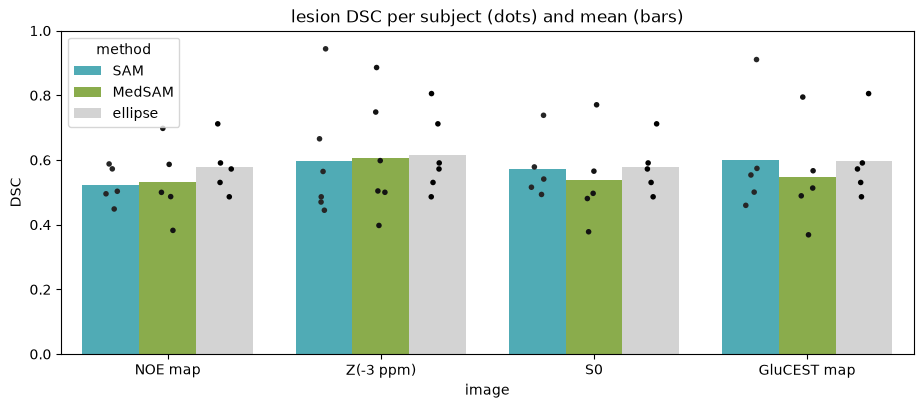

In [27]:
long = subject_df.melt(id_vars=['subject', 'image'], value_vars=['SAM DSC', 'MedSAM DSC', 'ellipse DSC'],
                       var_name='method', value_name='DSC')
long['method'] = long['method'].str.replace(' DSC', '')

plt.figure(figsize=(11, 4.2))
sns.barplot(data=long, x='image', y='DSC', hue='method', errorbar=None,
            palette={'SAM': '#3fb8c6', 'MedSAM': '#8fbc3c', 'ellipse': 'lightgray'})
sns.stripplot(data=long, x='image', y='DSC', hue='method', dodge=True, color='black', size=4, legend=False)
plt.ylim(0, 1)
plt.title('lesion DSC per subject (dots) and mean (bars)')
plt.show()

Per lesion piece, paired test (same lesions) MedSAM vs SAM and MedSAM vs the ellipse:

In [28]:
test_rows = []
for c in contrasts:
    p = piece_df[piece_df['image'] == c]
    if len(p) == 0:
        continue
    test_rows.append({'image': c, 'lesion pieces': len(p),
                      'MedSAM median DSC': p['MedSAM'].median(), 'SAM median DSC': p['SAM'].median(),
                      'ellipse median DSC': p['ellipse'].median(),
                      'p MedSAM vs SAM': wilcoxon(p['MedSAM'], p['SAM']).pvalue,
                      'p MedSAM vs ellipse': wilcoxon(p['MedSAM'], p['ellipse']).pvalue})
pd.DataFrame(test_rows).set_index('image').round(4)

,lesion pieces,MedSAM median DSC,SAM median DSC,ellipse median DSC,p MedSAM vs SAM,p MedSAM vs ellipse
image,,,,,,
GluCEST map,151,0.4390,0.5091,0.5116,0.0000,0.0
NOE map,157,0.4615,0.4776,0.5152,0.1224,0.0
Z(-3 ppm),162,0.4603,0.4791,0.5253,0.6438,0.0
S0,157,0.4474,0.5246,0.5152,0.0000,0.0


Pictures in the paper style (blue box, yellow segmentation, magenta lesion mask), for the slice with the most lesion:

In [29]:
def show_mask(ax, mask, color=(1, 1, 0), alpha=0.5):
    rgba = np.zeros(mask.shape + (4,))
    rgba[mask] = list(color) + [alpha]
    ax.imshow(rgba)

def paper_panel(ax, img, gt, boxes, pred, title):
    ax.imshow(img, cmap='gray')
    show_mask(ax, pred, alpha=0.5)
    ax.contour(gt, [0.5], colors='magenta', linewidths=1)
    for x0, y0, x1, y1 in boxes:
        ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor='blue', linewidth=1))
    ax.text(0.02, 0.97, f'DSC: {dice(pred, gt):.3f}', transform=ax.transAxes, color='yellow', fontsize=9, va='top',
            bbox=dict(facecolor='black', alpha=0.5, pad=1, edgecolor='none'))
    ax.set_title(title, fontsize=9)
    ax.axis('off')

def zoom_box(lesion_2d, pad=15):
    rows, cols = np.where(lesion_2d)
    return slice(max(rows.min() - pad, 0), rows.max() + pad), slice(max(cols.min() - pad, 0), cols.max() + pad)

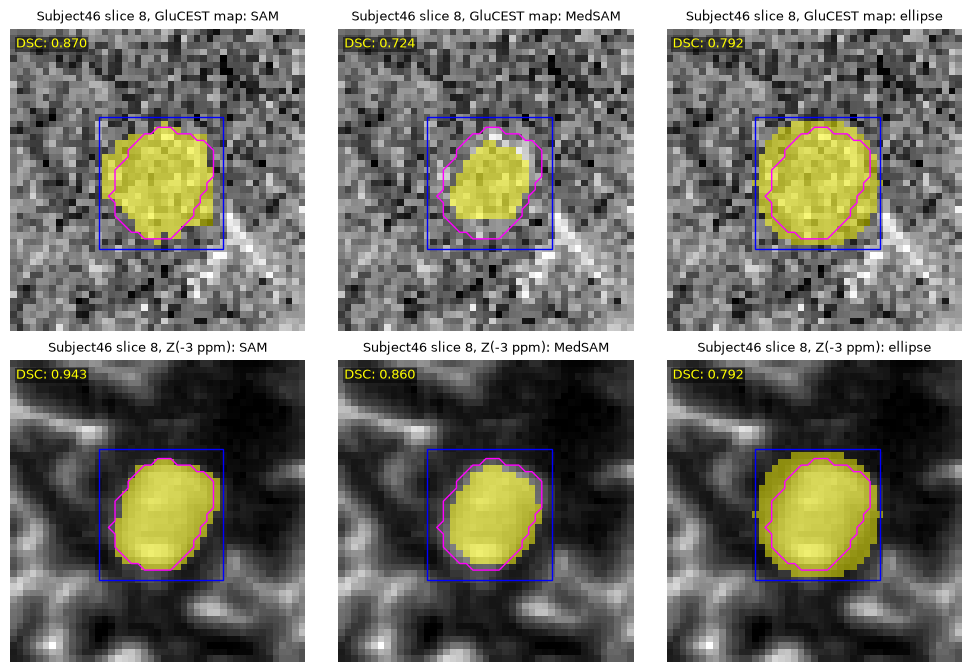

In [30]:
def subject_figure(name, image_types):
    d = subjects[name]
    used = middle_lesion_slices(d)
    z = used[np.argmax(d['lesion'][:, :, used].sum(axis=(0, 1)))]      # biggest lesion among the slices I used
    gt = d['lesion'][:, :, z]
    boxes, _ = lesion_boxes(gt)
    zr, zc = zoom_box(gt)
    shifted = boxes - np.array([zc.start, zr.start, zc.start, zr.start])
    fig, ax = plt.subplots(len(image_types), 3, figsize=(10, 3.4 * len(image_types)), squeeze=False)
    for r, c in enumerate(image_types):
        img = to_uint8(d[c][:, :, z], d['roi'][:, :, z])
        for k, method in enumerate(['SAM', 'MedSAM', 'ellipse']):
            pred = predictions[(name, c, method)][:, :, z]
            paper_panel(ax[r, k], img[zr, zc], gt[zr, zc], shifted, pred[zr, zc], f'{name} slice {z}, {c}: {method}')
    plt.tight_layout()
    plt.show()

subject_figure('Subject46', ['GluCEST map', 'Z(-3 ppm)'])

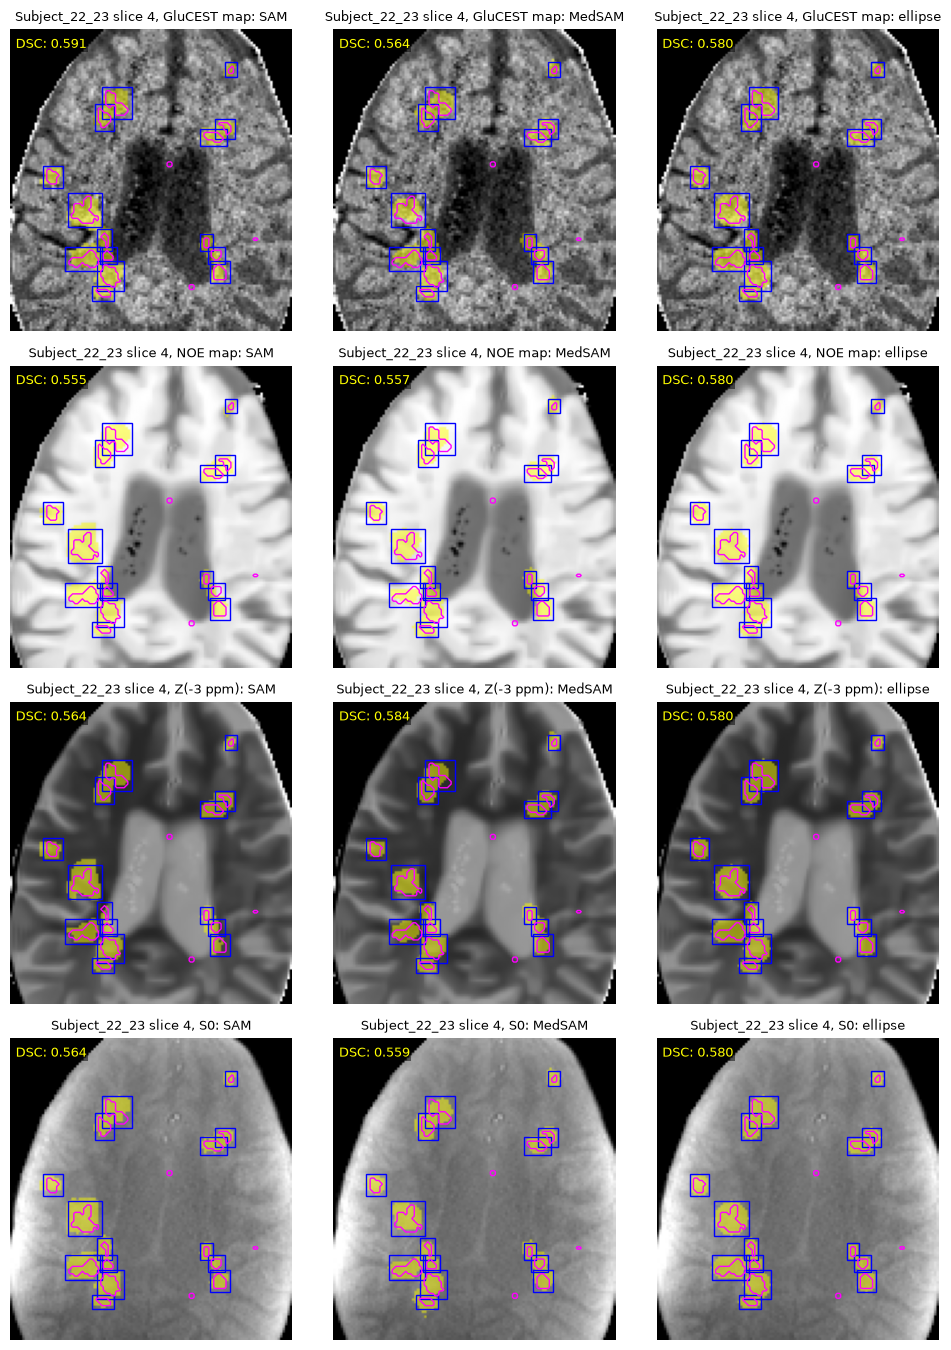

In [31]:
subject_figure('Subject_22_23', ['GluCEST map', 'NOE map', 'Z(-3 ppm)', 'S0'])

##### **On the 5 `MS_five_Sub` subjects MedSAM does not beat "fill the box with an ellipse"**: mean DSC 0.48-0.55 for MedSAM vs 0.55-0.58 for the ellipse depending on the image type, and per lesion the ellipse is significantly better (p < 0.001). SAM is about the same. That makes sense after the EDA: the lesion isn't visible in the image, so all a model can do is fill the box, and the ellipse does that best. The higher DSC for Subject_12_43 is just because its lesions are bigger.

##### **Subject46 is where it works**: on Z(-3 ppm) MedSAM gets DSC 0.89 vs 0.81 for the ellipse, so here it really follows the lesion edge. On the GluCEST map it's 0.80, the same as the ellipse; in the picture MedSAM draws the lesion too small on the noisy GluCEST map. SAM is even better on Subject46 (0.94 on Z(-3 ppm), 0.91 on GluCEST).

## 6. Small vs big lesions
In notebook 01, MedSAM did badly on tiny nuclei. Is it the same here? DSC per lesion piece against its size.

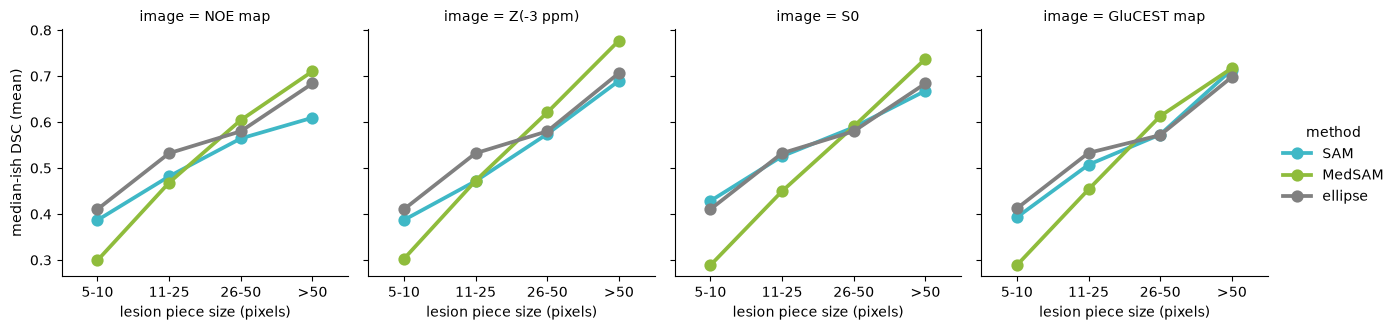

,MedSAM,SAM,ellipse
size group,,,
5-10,0.295,0.399,0.411
11-25,0.461,0.497,0.532
26-50,0.607,0.575,0.578
>50,0.738,0.671,0.694


In [32]:
piece_df['size group'] = pd.cut(piece_df['pixels'], [0, 10, 25, 50, 1000], labels=['5-10', '11-25', '26-50', '>50'])
size_long = piece_df.melt(id_vars=['image', 'size group'], value_vars=['SAM', 'MedSAM', 'ellipse'],
                          var_name='method', value_name='DSC')

g = sns.catplot(data=size_long, x='size group', y='DSC', hue='method', col='image', kind='point', errorbar=None,
                palette={'SAM': '#3fb8c6', 'MedSAM': '#8fbc3c', 'ellipse': 'gray'}, height=3.4, aspect=0.95)
g.set_axis_labels('lesion piece size (pixels)', 'median-ish DSC (mean)')
plt.show()

piece_df.groupby('size group', observed=True)[['MedSAM', 'SAM', 'ellipse']].mean().round(3)

##### Size matters a lot. For lesion pieces of 5-10 pixels MedSAM gets DSC 0.30, worse than the ellipse (0.41) and SAM (0.40). Above 25 pixels MedSAM becomes the best of the 3 (26-50 px: 0.61 vs 0.58 ellipse; >50 px: 0.74 vs 0.69). A 3 x 3 pixel lesion is smaller than one 16 x 16 patch of the image encoder after resizing to 1024, same problem as the pathology nuclei in notebook 01.

## 7. How exact does the box need to be?
Like section 8 of notebook 01, but on our lesions: move each box corner randomly by up to `shift` pixels (on the
240 x 196 slice; 1 pixel here is about 4-5 pixels on the 1024 image). On the Z(-3 ppm) image, which had the most
lesion contrast in the EDA, 3 tries per shift.

In [33]:
rng = np.random.default_rng(0)
robust_rows = []
for name, d in subjects.items():
    H, W, Zn = d['lesion'].shape
    for z in middle_lesion_slices(d):
        boxes, lab = lesion_boxes(d['lesion'][:, :, z])
        if len(boxes) == 0:
            continue
        gt = d['lesion'][:, :, z]
        emb = medsam_embedding(to_3_channels(to_uint8(d['Z(-3 ppm)'][:, :, z], d['roi'][:, :, z])))
        for shift in [0, 1, 2, 4]:
            for t in range(1 if shift == 0 else 3):
                b = boxes + rng.uniform(-shift, shift, size=boxes.shape)
                b[:, [0, 2]] = np.clip(np.sort(b[:, [0, 2]], axis=1), 0, W - 1)
                b[:, [1, 3]] = np.clip(np.sort(b[:, [1, 3]], axis=1), 0, H - 1)
                robust_rows.append({'subject': name, 'shift': shift,
                                    'MedSAM': dice(medsam_box(emb, b, H, W).any(axis=0), gt),
                                    'ellipse': dice(ellipse_in_box(b, H, W).any(axis=0), gt)})
robust_df = pd.DataFrame(robust_rows)
robust_df.groupby('shift')[['MedSAM', 'ellipse']].mean().round(3)

,MedSAM,ellipse
shift,,
0,0.614,0.620
1,0.612,0.605
2,0.590,0.593
4,0.515,0.493


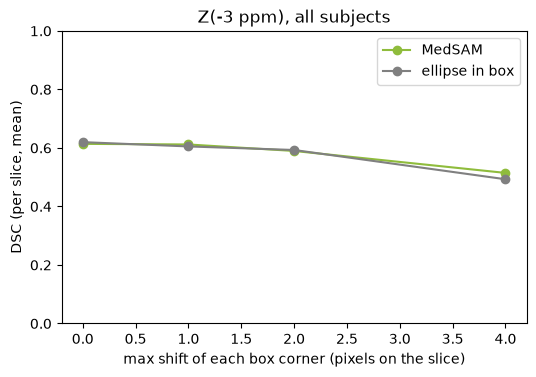

In [34]:
plt.figure(figsize=(6, 3.8))
means = robust_df.groupby('shift')[['MedSAM', 'ellipse']].mean()
plt.plot(means.index, means['MedSAM'], 'o-', color='#8fbc3c', label='MedSAM')
plt.plot(means.index, means['ellipse'], 'o-', color='gray', label='ellipse in box')
plt.xlabel('max shift of each box corner (pixels on the slice)')
plt.ylabel('DSC (per slice, mean)')
plt.ylim(0, 1)
plt.legend()
plt.title('Z(-3 ppm), all subjects')
plt.show()

##### Shifting the box corners by 1-2 pixels changes almost nothing (0.614 -> 0.590), 4 pixels drops it to 0.515. On these small lesions 4 pixels is about the size of the lesion itself, so that's expected. MedSAM and the ellipse behave the same, again because there is little lesion signal for MedSAM to follow.

## 8. 3D with sparse markers (Fig. 5b) on the Subject46 lesion
The Subject46 lesion is one round lesion over several slices. Like in the paper's annotation study: draw a marker box on
only some slices, interpolate the boxes in between, MedSAM on every slice. On the GluCEST map and on Z(-3 ppm).

In [35]:
d = subjects['Subject46']
les_slices = np.where(d['lesion'].any(axis=(0, 1)))[0]
print('lesion on slices', les_slices)

def run_markers(image_type, marker_slices):
    H, W, Zn = d['lesion'].shape
    marker_boxes = np.array([box_from_mask(d['lesion'][:, :, z]) for z in marker_slices])
    pred = np.zeros((H, W, Zn), bool)
    for z in les_slices:
        box = np.array([np.interp(z, marker_slices, marker_boxes[:, j]) for j in range(4)])
        img = to_3_channels(to_uint8(d[image_type][:, :, z], d['roi'][:, :, z]))
        pred[:, :, z] = medsam_box(medsam_embedding(img), [box], H, W)[0] & d['roi'][:, :, z]
    return pred

lesion on slices [2 3 4 5 6 7 8 9]


In [36]:
marker_rows = []
marker_preds = {}
for image_type in ['GluCEST map', 'Z(-3 ppm)']:
    for every in [1, 2, 4]:
        markers = list(les_slices[::every])
        if markers[-1] != les_slices[-1]:
            markers.append(les_slices[-1])
        pred = run_markers(image_type, markers)
        marker_preds[(image_type, every)] = pred
        marker_rows.append({'image': image_type, 'marker every': every, 'boxes drawn': len(markers),
                            '3D DSC': dice(pred, d['lesion']), '3D NSD': nsd(pred, d['lesion'], spacing=(1, 1, 2)),
                            'volume mL': pred.sum() * 2 / 1000})
print(f"lesion volume (mask): {d['lesion'].sum() * 2 / 1000:.2f} mL")
pd.DataFrame(marker_rows).round(3)

lesion volume (mask): 3.17 mL


,image,marker every,boxes drawn,3D DSC,3D NSD,volume mL
0,GluCEST map,1,8,0.810,0.939,2.420
1,GluCEST map,2,5,0.801,0.933,2.372
2,GluCEST map,4,3,0.830,0.945,2.582
3,Z(-3 ppm),1,8,0.869,0.980,2.714
4,Z(-3 ppm),2,5,0.854,0.980,2.656
5,Z(-3 ppm),4,3,0.870,0.982,2.886


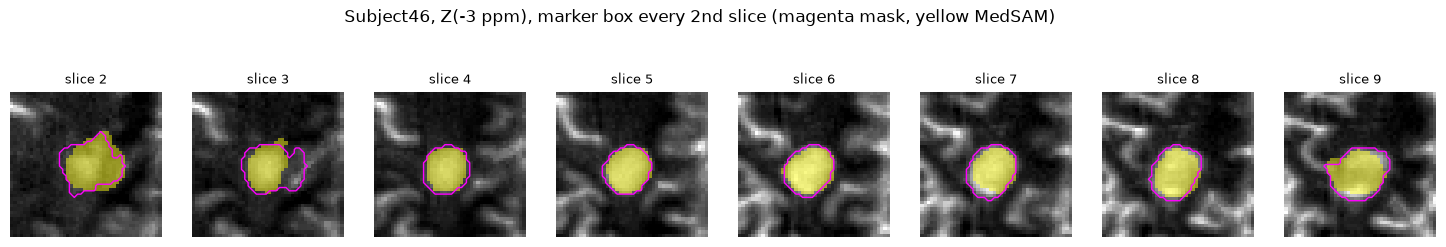

In [37]:
pred = marker_preds[('Z(-3 ppm)', 2)]
zr, zc = zoom_box(d['lesion'].any(axis=2), pad=12)
fig, ax = plt.subplots(1, len(les_slices), figsize=(2.3 * len(les_slices), 2.8))
for a, z in zip(ax, les_slices):
    a.imshow(to_uint8(d['Z(-3 ppm)'][:, :, z], d['roi'][:, :, z])[zr, zc], cmap='gray')
    show_mask(a, pred[zr, zc, z], alpha=0.45)
    a.contour(d['lesion'][zr, zc, z], [0.5], colors='magenta', linewidths=1)
    a.set_title(f'slice {z}', fontsize=9)
    a.axis('off')
plt.suptitle('Subject46, Z(-3 ppm), marker box every 2nd slice (magenta mask, yellow MedSAM)', y=1.05)
plt.show()

##### With only 3 marker boxes (every 4th slice) instead of 8, MedSAM gets the same 3D result: DSC 0.87 on Z(-3 ppm) and 0.83 on the GluCEST map. It does underestimate the volume (2.4-2.9 mL vs 3.17 mL in the mask), it draws the lesion a bit smaller than the mask.

## 9. What I learned

| | MedSAM | SAM | ellipse in the box |
|---|---|---|---|
| 5 `MS_five_Sub` subjects, GluCEST map (4 subjects) | 0.48 | 0.52 | 0.55 |
| 5 `MS_five_Sub` subjects, NOE map | 0.53 | 0.52 | 0.58 |
| 5 `MS_five_Sub` subjects, Z(-3 ppm) | 0.55 | 0.53 | 0.58 |
| Subject46, GluCEST map | 0.80 | 0.91 | 0.81 |
| Subject46, Z(-3 ppm) | 0.89 | 0.94 | 0.81 |

(mean DSC over subjects, 5 middle lesion slices each)

1. **MedSAM can only outline what is visible.** On the 5 `MS_five_Sub` subjects the lesions are not visible on the
   GluCEST, NOE, Z(-3 ppm) or S0 images (|d'| <= 0.21), and MedSAM is no better than filling the box with an ellipse.
   The box carries all the information.
2. **When the lesion is visible it works.** Subject46's lesion has strong MT contrast, and on Z(-3 ppm) MedSAM follows
   its edge (DSC 0.89 vs 0.81 for the ellipse), and 3 marker boxes are enough for the 3D lesion (DSC 0.87).
3. **On the GluCEST map itself** even Subject46's lesion is only moderately visible (d' 1.1) and MedSAM draws it too
   small (0.80, same as the ellipse). Plain SAM did better on Subject46.
4. **Tiny lesions are the main problem**: below ~25 pixels MedSAM is worse than the ellipse; above that it's the best.
5. Compared with notebook 01 (public data, DSC ~0.9+): the drop here is mostly the data (small, low-contrast lesions at
   CEST resolution), not the model.

**Caveats**: 6 MS subjects, 5 middle slices each (`N_SLICES`). Subject46's mask is semi-automatic and made from
Z(-3 ppm), so its Z(-3 ppm) result is partly circular. The `MS_five_Sub` masks are hand-drawn, I don't know on which
scan, and some may not line up perfectly with the CEST slab.

**What would help**: give MedSAM an image where the lesions are visible (FLAIR or MP2RAGE resampled to the CEST slab),
segment there, then read the GluCEST / NOE values inside the MedSAM mask. That's the use the paper is built for:
outline the lesion on the anatomy, then measure the biomarker inside it.